In [6]:

import pandas as pd
import numpy as np
import re
import random
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

print("All libraries imported successfully!")


All libraries imported successfully!


In [7]:

fake_df = pd.read_csv("/content/fake.csv")
real_df = pd.read_csv("/content/true.csv")

print("FAKE NEWS DATASET")
print(fake_df.head())

print("\nREAL NEWS DATASET")
print(real_df.head())

print("\nFake dataset shape:", fake_df.shape)
print("Real dataset shape:", real_df.shape)

print("\nColumn names:")
print(fake_df.columns.tolist())


FAKE NEWS DATASET
                                               title  \
0   Donald Trump Sends Out Embarrassing New Year’...   
1   Drunk Bragging Trump Staffer Started Russian ...   
2   Sheriff David Clarke Becomes An Internet Joke...   
3   Trump Is So Obsessed He Even Has Obama’s Name...   
4   Pope Francis Just Called Out Donald Trump Dur...   

                                                text subject  \
0  Donald Trump just couldn t wish all Americans ...    News   
1  House Intelligence Committee Chairman Devin Nu...    News   
2  On Friday, it was revealed that former Milwauk...    News   
3  On Christmas day, Donald Trump announced that ...    News   
4  Pope Francis used his annual Christmas Day mes...    News   

                date  
0  December 31, 2017  
1  December 31, 2017  
2  December 30, 2017  
3  December 29, 2017  
4  December 25, 2017  

REAL NEWS DATASET
                                               title  \
0  As U.S. budget fight looms, Republicans flip

In [8]:

# Assign labels: 0 = Fake, 1 = Real
fake_df["label"] = 0
real_df["label"] = 1

# Combine both datasets
df = pd.concat([fake_df, real_df], ignore_index=True)

# Handle missing values
df["title"] = df["title"].fillna("")
df["text"] = df["text"].fillna("")

# Combine title and article text
df["content"] = df["title"] + " " + df["text"]

# Remove empty articles and duplicates
df = df[df["content"].str.strip() != ""]
df = df.drop_duplicates(subset=["content"])

# Select 1000 fake + 1000 real articles
fake_news = df[df["label"] == 0]
real_news = df[df["label"] == 1]

n = min(1000, len(fake_news), len(real_news))

df = pd.concat([
    fake_news.sample(n=n, random_state=42),
    real_news.sample(n=n, random_state=42)
], ignore_index=True)

# Shuffle articles
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

print("Total articles:", len(df))
print("\nClass distribution:")
print(df["label"].value_counts())

print("\nSample news article:")
print(df["content"].iloc[0])


Total articles: 2000

Class distribution:
label
1    1000
0    1000
Name: count, dtype: int64

Sample news article:
White House discussing moving Spicer to new communications role: official WASHINGTON (Reuters) - The White House is considering shifting press secretary Sean Spicer away from the daily spokesman job and into a new communications role but no such move is believed imminent, a senior White House official said on Monday. Spicer has been a frequent target of criticism for his performance at the White House lectern during daily news briefings, although President Donald Trump has stood by him through a variety of controversies. Spicer, who was the Republican National Committee’s senior strategist during the presidential campaign last year, is currently doing double duty as press secretary and communications director after the previous communications director, Michael Dubke, resigned May 30. The senior White House official, who spoke on condition of anonymity, said discussions ab

In [9]:

# Text preprocessing
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["content"] = df["content"].apply(clean_text)

# Remove any empty articles after cleaning
df = df[df["content"].str.strip() != ""].reset_index(drop=True)

print("Text preprocessing completed!")
print("\nSample cleaned article:")
print(df["content"].iloc[0])

print("\nTotal articles after cleaning:", len(df))


Text preprocessing completed!

Sample cleaned article:
white house discussing moving spicer to new communications role official washington reuters the white house is considering shifting press secretary sean spicer away from the daily spokesman job and into a new communications role but no such move is believed imminent a senior white house official said on monday spicer has been a frequent target of criticism for his performance at the white house lectern during daily news briefings although president donald trump has stood by him through a variety of controversies spicer who was the republican national committee s senior strategist during the presidential campaign last year is currently doing double duty as press secretary and communications director after the previous communications director michael dubke resigned may the senior white house official who spoke on condition of anonymity said discussions about some changes in the communications department have been going on for some ti

In [10]:

X = df["content"].values
y = df["label"].values

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training articles:", len(X_train))
print("Testing articles:", len(X_test))


Training articles: 1600
Testing articles: 400


In [11]:

VOCAB_SIZE = 10000
MAX_LENGTH = 300

tokenizer = Tokenizer(
    num_words=VOCAB_SIZE,
    oov_token="<OOV>"
)

# Learn vocabulary from training data only
tokenizer.fit_on_texts(X_train)

# Convert words into numerical sequences
X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

# Make all sequences the same length
X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

print("Tokenization and padding completed!")
print("Training shape:", X_train_pad.shape)
print("Testing shape:", X_test_pad.shape)
print("\nFirst 20 numerical tokens:")
print(X_train_pad[0][:20])


Tokenization and padding completed!
Training shape: (1600, 300)
Testing shape: (400, 300)

First 20 numerical tokens:
[  71  487    3  916  157   10 2061  988 1430   87   65  112   69   36
    8   38  348   71   12  487]


In [12]:

model = Sequential([
    Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=64,
        mask_zero=True
    ),
    LSTM(64),
    Dropout(0.4),
    Dense(32, activation="relu"),
    Dropout(0.3),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [13]:

model.build(input_shape=(None, 300))
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 300, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 675,137 (2.58 MB)

 Trainable params: 675,137 (2.58 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    X_train_pad,
    y_train,
    epochs=8,
    batch_size=32,
    validation_split=0.15,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/8
43/43 ━━━━━━━━━━━━━━━━━━━━ 12s 211ms/step - accuracy: 0.5235 - loss: 0.6888 - val_accuracy: 0.7833 - val_loss: 0.6491
Epoch 2/8
43/43 ━━━━━━━━━━━━━━━━━━━━ 9s 190ms/step - accuracy: 0.8794 - loss: 0.4078 - val_accuracy: 0.9417 - val_loss: 0.3730
Epoch 3/8
43/43 ━━━━━━━━━━━━━━━━━━━━ 11s 213ms/step - accuracy: 0.8801 - loss: 0.3605 - val_accuracy: 0.8708 - val_loss: 0.4247
Epoch 4/8
43/43 ━━━━━━━━━━━━━━━━━━━━ 10s 222ms/step - accuracy: 0.9221 - loss: 0.2587 - val_accuracy: 0.8875 - val_loss: 0.3867


In [15]:

probabilities = model.predict(X_test_pad, verbose=0).ravel()
y_pred = (probabilities >= 0.5).astype(int)

print("========== MODEL EVALUATION ==========")
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-score :", round(f1_score(y_test, y_pred, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Fake News", "Real News"],
    zero_division=0
))


========== MODEL EVALUATION ==========
Accuracy : 0.9
Precision: 0.9301
Recall   : 0.865
F1-score : 0.8964

Classification Report:
              precision    recall  f1-score   support

   Fake News       0.87      0.94      0.90       200
   Real News       0.93      0.86      0.90       200

    accuracy                           0.90       400
   macro avg       0.90      0.90      0.90       400
weighted avg       0.90      0.90      0.90       400



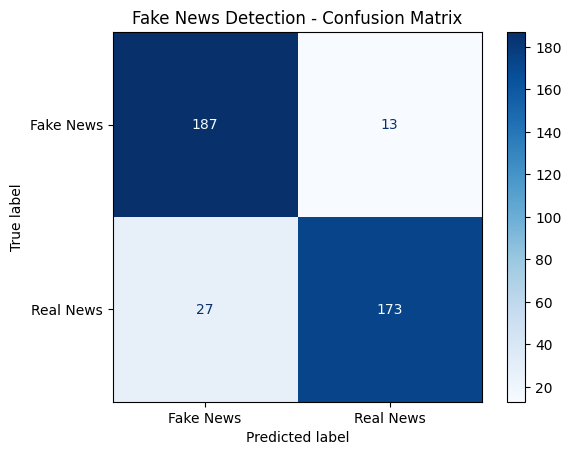

In [16]:

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Fake News", "Real News"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Fake News Detection - Confusion Matrix")
plt.show()


In [17]:

def predict_news(news_text):
    cleaned = clean_text(news_text)

    if not cleaned:
        print("Please enter valid news text.")
        return

    sequence = tokenizer.texts_to_sequences([cleaned])
    padded = pad_sequences(
        sequence,
        maxlen=300,
        padding="post",
        truncating="post"
    )

    score = float(model.predict(padded, verbose=0)[0][0])
    label = "REAL NEWS" if score >= 0.5 else "FAKE NEWS"

    print("\nArticle:", news_text)
    print("Prediction:", label)
    print("Real News score:", round(score, 4))
    print("Note: This is a model prediction, not a verified fact-check.")

predict_news(
    "The government announced a new public transport scheme "
    "to improve connectivity in rural areas."
)

predict_news(
    "A viral online post claims that a secret drink cures "
    "every disease instantly."
)



Article: The government announced a new public transport scheme to improve connectivity in rural areas.
Prediction: REAL NEWS
Real News score: 0.6278
Note: This is a model prediction, not a verified fact-check.

Article: A viral online post claims that a secret drink cures every disease instantly.
Prediction: FAKE NEWS
Real News score: 0.3244
Note: This is a model prediction, not a verified fact-check.


In [18]:

probabilities = model.predict(X_test_pad, verbose=0).ravel()
y_pred = (probabilities >= 0.5).astype(int)

print("========== MODEL EVALUATION ==========")
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-score :", round(f1_score(y_test, y_pred, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Fake News", "Real News"],
    zero_division=0
))


========== MODEL EVALUATION ==========
Accuracy : 0.9
Precision: 0.9301
Recall   : 0.865
F1-score : 0.8964

Classification Report:
              precision    recall  f1-score   support

   Fake News       0.87      0.94      0.90       200
   Real News       0.93      0.86      0.90       200

    accuracy                           0.90       400
   macro avg       0.90      0.90      0.90       400
weighted avg       0.90      0.90      0.90       400



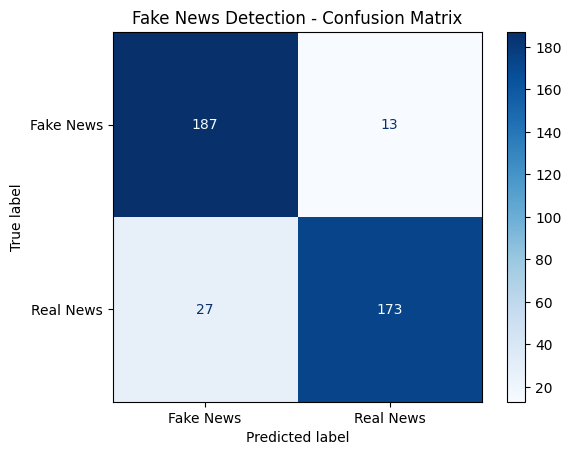

In [19]:

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Fake News", "Real News"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Fake News Detection - Confusion Matrix")
plt.show()


In [20]:

def predict_news(news_text):
    cleaned = clean_text(news_text)

    if not cleaned:
        print("Please enter valid news text.")
        return

    sequence = tokenizer.texts_to_sequences([cleaned])

    padded = pad_sequences(
        sequence,
        maxlen=300,
        padding="post",
        truncating="post"
    )

    score = float(model.predict(padded, verbose=0)[0][0])

    label = "REAL NEWS" if score >= 0.5 else "FAKE NEWS"

    print("\nArticle:", news_text)
    print("Prediction:", label)
    print("Real News score:", round(score, 4))
    print("Note: Model prediction only; not a verified fact-check.")

predict_news(
    "The government announced a new public transport scheme "
    "to improve connectivity in rural areas."
)

predict_news(
    "A viral online post claims that a secret drink cures "
    "every disease instantly."
)



Article: The government announced a new public transport scheme to improve connectivity in rural areas.
Prediction: REAL NEWS
Real News score: 0.6278
Note: Model prediction only; not a verified fact-check.

Article: A viral online post claims that a secret drink cures every disease instantly.
Prediction: FAKE NEWS
Real News score: 0.3244
Note: Model prediction only; not a verified fact-check.
